In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df1=pd.read_csv("Students Social Media Addiction.csv")
df2=pd.read_excel("SocialMedia_Project (Responses).xlsx")
final_df=pd.concat([df1,df2],ignore_index=True)

In [3]:
columns=final_df.columns
categorical_features=[feature for feature in columns if final_df[feature].dtype=="O"]
numerical_features=[feature for feature in columns if final_df[feature].dtype!="O"]

In [4]:
final_df.columns

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score', 'Relationship_Status',
       'Conflicts_Over_Social_Media', 'Addicted_Score'],
      dtype='object')

In [5]:
# ML Pipeline
# 1. data ingestion
# 2. EDA
# 3. Data preparation
# 4. X,Y
# 5. Train test split
# 6. model building
# 7. model evaluation

In [6]:
# possible target variables we have are: 
# 1. Addicted_Score(1-10) - Regression model, 
# 2. Affects_Academic_Performance(Yes, No) - classification model, 
# 3. Mental_Health_Score(1-10) - Regression model

1st Model: Simple linear model: 
Independent variable: 'Addicted_Score'
Dependent variable: "Avg_Daily_Usage_Hours"

In [7]:
# 1st model- simple linear regression model
# problem statement: How does the average daily usage of social media affect the addiction score?
x=final_df["Avg_Daily_Usage_Hours"]
y=final_df['Addicted_Score']
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=1)
from sklearn.linear_model import LinearRegression
slr_model=LinearRegression()
slr_model.fit(pd.DataFrame(x_train),pd.DataFrame(y_train))

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
print("Model's Coefficient is: ",slr_model.coef_)
print("Model's Intercept is: ",slr_model.intercept_)
# y = theta0 + theta1*X: here, theta0 is intercept and theta1 is coefficient
# y = 1.39 + 1.82*x
# this means with 1 unit change in number of hours spent on social media on daily basis, there is 1.8 units change in addiction score.
# also this means that the average addiction score or we can say the starting point of the addiction score is 1.39

Model's Coefficient is:  [[1.02681141]]
Model's Intercept is:  [1.39378957]


In [9]:
y_pred=slr_model.predict(pd.DataFrame(x_test))

In [10]:
y_pred

array([[ 5.09031065],
       [ 5.91175978],
       [ 6.11712206],
       [ 8.27342602],
       [ 5.91175978],
       [ 7.65733917],
       [ 5.19299179],
       [ 9.09487515],
       [ 7.45197689],
       [ 6.42516548],
       [ 7.45197689],
       [ 6.01444092],
       [ 5.50103521],
       [ 5.39835407],
       [ 7.34929575],
       [ 9.09487515],
       [ 7.34929575],
       [ 3.65277467],
       [ 5.70639749],
       [ 8.4787883 ],
       [ 6.93857119],
       [ 6.2198032 ],
       [ 6.42516548],
       [ 8.58146944],
       [ 6.32248434],
       [ 8.4787883 ],
       [ 2.42060098],
       [ 8.27342602],
       [ 7.45197689],
       [ 7.04125233],
       [ 5.70639749],
       [ 8.68415058],
       [ 7.34929575],
       [ 6.2198032 ],
       [ 7.24661461],
       [ 5.80907863],
       [ 7.24661461],
       [ 7.9653826 ],
       [ 7.9653826 ],
       [ 4.4742238 ],
       [ 6.42516548],
       [ 8.58146944],
       [ 8.58146944],
       [ 5.29567293],
       [ 6.01444092],
       [ 5

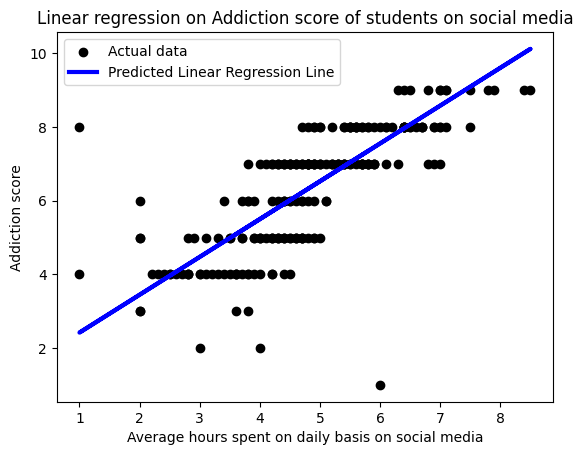

In [11]:
# visualise the result
plt.scatter(x_test,y_test,color='black',label='Actual data')
plt.plot(x_test,y_pred,color='blue',linewidth=3,label='Predicted Linear Regression Line')
plt.xlabel("Average hours spent on daily basis on social media")
plt.ylabel("Addiction score")
plt.title("Linear regression on Addiction score of students on social media")
plt.legend()
plt.show()

In [12]:
# evaluation
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.5615984041890609

In [13]:
# as the above model is just 50% accurate, we will try fitting Multiple linear regression, as in simple linear regression, it is not predicting/ performing that well. 
# total features: 13, target var
# Target: Addicted_Score,  Affects_Academic_Performance,Mental_Health_Score
numerical_features
# encoding required: 'Most_Used_Platform', 'Affects_Academic_Performance'
# mlr-model-parameters: 'Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Conflicts_Over_Social_Media''Academic_Level','Country','Most_Used_Platform'

['Student_ID',
 'Age',
 'Avg_Daily_Usage_Hours',
 'Sleep_Hours_Per_Night',
 'Mental_Health_Score',
 'Conflicts_Over_Social_Media',
 'Addicted_Score']

In [14]:
categorical_features

['Gender',
 'Academic_Level',
 'Country',
 'Most_Used_Platform',
 'Affects_Academic_Performance',
 'Relationship_Status']

In [15]:
# columns for Multi linear regression: 
# X:
# Numerical: 1.'Avg_Daily_Usage_Hours',2. 'Sleep_Hours_Per_Night',3.'Mental_Health_Score',4.'Conflicts_Over_Social_Media'
# Categorical:1.'Academic_Level',2.'Most_Used_Platform',3.'Affects_Academic_Performance'
# Y:'Addicted_Score'
# columns that need encoding: 1.'Academic_Level',2.'Most_Used_Platform',3.'Affects_Academic_Performance'

In [16]:
# encoding: using labelEncoder
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
final_df["Academic_Level"]=encoder.fit_transform(final_df["Academic_Level"])
final_df["Affects_Academic_Performance"]=encoder.fit_transform(final_df["Affects_Academic_Performance"])
final_df['Gender']=encoder.fit_transform(final_df['Gender'])

In [17]:
print("Unique values of Academic_Level: ",final_df["Academic_Level"].unique()) 
print("Value counts of coresponding Unique values: ",final_df["Academic_Level"].value_counts().unique())
# here: 2 is Graduate level, 0 is high school, 1 is Under Graduate level
print("Unique values of Affects_Academic_Performance: ",final_df["Affects_Academic_Performance"].unique())
print("Value counts of coresponding Unique values: ",final_df["Affects_Academic_Performance"].value_counts().unique())
# 0 is for no, 1 is for yes
print("Unique values of Gender: ",final_df["Gender"].unique())
print("Value counts of coresponding Unique values: ",final_df["Gender"].value_counts().unique())
# 0 is for Female, 1 is for Male

Unique values of Academic_Level:  [2 0 1]
Value counts of coresponding Unique values:  [378 325  27]
Unique values of Affects_Academic_Performance:  [1 0]
Value counts of coresponding Unique values:  [468 262]
Unique values of Gender:  [0 1]
Value counts of coresponding Unique values:  [378 352]


In [18]:
# encoding for this attribute will be different: as this doesnot has any definite pattern, so one hot encoding will be done
print("Unique values of Most_Used_Platform are:",final_df.Most_Used_Platform.unique())
from sklearn.preprocessing import OneHotEncoder
onehotencoder=OneHotEncoder()
encoded=onehotencoder.fit_transform(final_df[["Most_Used_Platform"]]).toarray()
print("Encoded values are: ",encoded)
print("Feature names: ",onehotencoder.get_feature_names_out())
encoder_df=pd.DataFrame(encoded,columns=onehotencoder.get_feature_names_out())

Unique values of Most_Used_Platform are: ['Instagram' 'Twitter' 'TikTok' 'YouTube' 'Facebook' 'LinkedIn' 'Snapchat'
 'LINE' 'KakaoTalk' 'VKontakte' 'WhatsApp' 'WeChat' 'WhatsApp '
 'You tube ' 'instagram' 'Instagram ' 'YouTube ' 'Youtube' 'Whatsapp ']
Encoded values are:  [[0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 1. 0. 0.]]
Feature names:  ['Most_Used_Platform_Facebook' 'Most_Used_Platform_Instagram'
 'Most_Used_Platform_Instagram ' 'Most_Used_Platform_KakaoTalk'
 'Most_Used_Platform_LINE' 'Most_Used_Platform_LinkedIn'
 'Most_Used_Platform_Snapchat' 'Most_Used_Platform_TikTok'
 'Most_Used_Platform_Twitter' 'Most_Used_Platform_VKontakte'
 'Most_Used_Platform_WeChat' 'Most_Used_Platform_WhatsApp'
 'Most_Used_Platform_WhatsApp ' 'Most_Used_Platform_Whatsapp '
 'Most_Used_Platform_You tube ' 'Most_Used_Platform_YouTube'
 'Most_Used_Platform_YouTube ' 'Most_Used_Platform_Youtube'
 'Most_Us

In [19]:
final_df=pd.concat([final_df,encoder_df],axis=1)
# as this encoded dataset has duplicated values, so we need to reform them
from collections import defaultdict
# copy to avoid modifying original (optional)
final_df = final_df.copy()
# Step 1: Clean column names
final_df.columns = final_df.columns.str.strip()
# Step 2: Group columns
platform_groups = defaultdict(list)
for col in final_df.columns:
    if col.startswith('Most_Used_Platform_'):
        platform = col.replace('Most_Used_Platform_', '').strip().lower()
        platform_groups[platform].append(col)

# Step 3: Merge safely
for platform, cols in platform_groups.items():
    new_col = 'Most_Used_Platform_' + platform

    if len(cols) > 1:
        # merge duplicates
        final_df[new_col] = final_df[cols].max(axis=1)

        # drop ONLY old columns (not the new one)
        cols_to_drop = [c for c in cols if c != new_col]
        final_df.drop(columns=cols_to_drop, inplace=True)

    else:
        # normalize single column name
        if cols[0] != new_col:
            final_df.rename(columns={cols[0]: new_col}, inplace=True)

# Step 4: Remove any accidental duplicates
final_df = final_df.loc[:, ~final_df.columns.duplicated()]

print(final_df.columns)

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score', 'Relationship_Status',
       'Conflicts_Over_Social_Media', 'Addicted_Score',
       'Most_Used_Platform_facebook', 'Most_Used_Platform_kakaotalk',
       'Most_Used_Platform_line', 'Most_Used_Platform_linkedin',
       'Most_Used_Platform_snapchat', 'Most_Used_Platform_tiktok',
       'Most_Used_Platform_twitter', 'Most_Used_Platform_vkontakte',
       'Most_Used_Platform_wechat', 'Most_Used_Platform_you tube',
       'Most_Used_Platform_instagram', 'Most_Used_Platform_whatsapp',
       'Most_Used_Platform_youtube'],
      dtype='object')


In [20]:
final_df["Most_Used_Platform_you tube"].value_counts()

Most_Used_Platform_you tube
0.0    729
1.0      1
Name: count, dtype: int64

In [21]:
final_df["Most_Used_Platform_youtube"].value_counts()

Most_Used_Platform_youtube
0.0    713
1.0     17
Name: count, dtype: int64

In [22]:
# the only duplicate column left is "Most_Used_Platform_you tube" and as it has only 1 yes, so we decide to drop this column
final_df=final_df.drop(["Most_Used_Platform_you tube"],axis=1)

In [23]:
# creating a copy of the final data frame and removing all the extra columns in order to build a multiple linear regression model
mlr_df=final_df.copy()
mlr_df.columns
mlr_df=mlr_df.drop(["Student_ID","Age","Country","Relationship_Status","Most_Used_Platform","Gender",'Most_Used_Platform_facebook', 'Most_Used_Platform_kakaotalk','Most_Used_Platform_line', 'Most_Used_Platform_linkedin','Most_Used_Platform_snapchat', 'Most_Used_Platform_tiktok','Most_Used_Platform_twitter', 'Most_Used_Platform_vkontakte','Most_Used_Platform_wechat', 'Most_Used_Platform_instagram','Most_Used_Platform_whatsapp', 'Most_Used_Platform_youtube'],axis=1)
mlr_df.columns
# now, our dataset is finally ready to perform MLR on it

Index(['Academic_Level', 'Avg_Daily_Usage_Hours',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score', 'Conflicts_Over_Social_Media', 'Addicted_Score'],
      dtype='object')

2nd model: Multiple linear regression model
Independent variables: 'Academic_Level', 'Avg_Daily_Usage_Hours','Affects_Academic_Performance', 'Sleep_Hours_Per_Night','Mental_Health_Score', 'Conflicts_Over_Social_Media'
Dependent variable: 'Addicted_Score'

In [24]:
# we will build 2 MLR models : 1. with target "Addiction score", 2. "Mental health score"
# Multiple linear regression: 1. with target "Addiction score"
X=mlr_df.drop(["Addicted_Score"],axis=1)
Y=mlr_df["Addicted_Score"]

In [25]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.3,random_state=1)
mlr_model=LinearRegression()
mlr_model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [26]:
print("Model's Coefficient is: ",mlr_model.coef_)
print("Model's Intercept is: ",mlr_model.intercept_)
# y = theta0 + theta1*X: here, theta0 is intercept and theta1 is coefficient
# y = 5.15 + (-0.05*x1) + (0.23*x2) + (0.64*x3) + (-0.06*x4) + (-0.32*x5) + (0.66*x6) 

Model's Coefficient is:  [-0.05514538  0.2377898   0.64592512 -0.06735377 -0.32919975  0.66094955]
Model's Intercept is:  5.515524520867293


In [27]:
y_pred=mlr_model.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)
# the model has imporved very much

0.8097001881876406

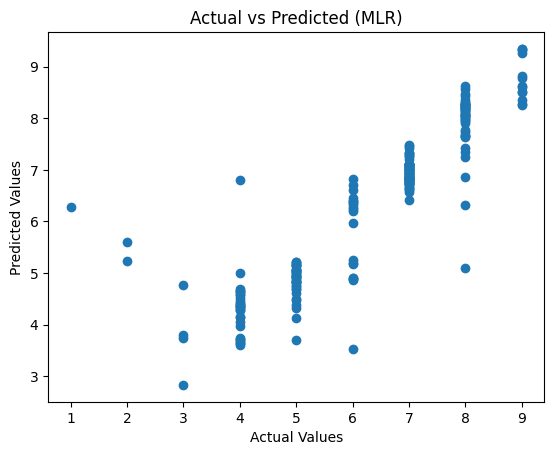

In [28]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (MLR)")
plt.show()

In [29]:
# points are mot much scattered so it is a good model

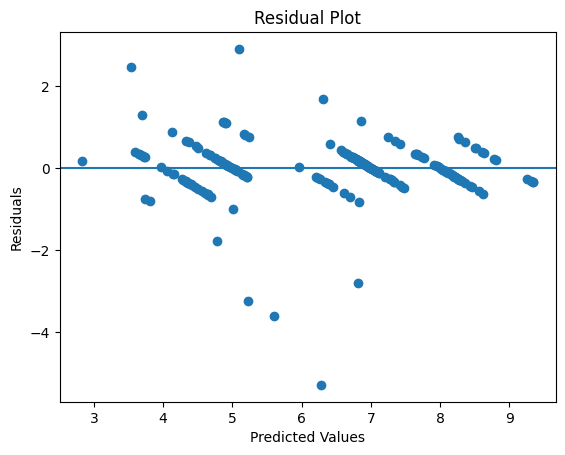

In [30]:
residuals = y_test - y_pred

plt.figure()
plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

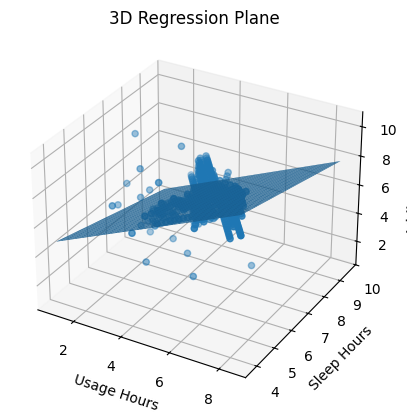

In [31]:
from mpl_toolkits.mplot3d import Axes3D
# Use only 2 features for visualization
X = mlr_df[['Avg_Daily_Usage_Hours', 'Sleep_Hours_Per_Night']]
y = mlr_df['Addicted_Score']
model = LinearRegression()
model.fit(X, y)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Scatter plot
ax.scatter(X.iloc[:,0], X.iloc[:,1], y)
# Create grid
x_surf, y_surf = np.meshgrid(
    np.linspace(X.iloc[:,0].min(), X.iloc[:,0].max(), 100),
    np.linspace(X.iloc[:,1].min(), X.iloc[:,1].max(), 100)
)
z_surf = model.intercept_ + model.coef_[0]*x_surf + model.coef_[1]*y_surf
# Surface plot
ax.plot_surface(x_surf, y_surf, z_surf)
ax.set_xlabel("Usage Hours")
ax.set_ylabel("Sleep Hours")
ax.set_zlabel("Addicted Score")
plt.title("3D Regression Plane")
plt.show()

In [32]:
coeff_df = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
print(coeff_df)

                       Coefficient
Avg_Daily_Usage_Hours     0.723631
Sleep_Hours_Per_Night    -0.427997


3rd model: Multiple linear Regression model. 
Independent variables: 'Academic_Level', 'Avg_Daily_Usage_Hours','Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Conflicts_Over_Social_Media', 'Addicted_Score'
Dependent variable: 'Mental_Health_Score'

In [33]:
mlr_df.columns
mlr_df['Affects_Academic_Performance']

0      1
1      0
2      1
3      0
4      1
      ..
725    0
726    1
727    0
728    0
729    1
Name: Affects_Academic_Performance, Length: 730, dtype: int64

In [34]:
mlr_df.columns[4]

'Mental_Health_Score'

In [35]:
X=mlr_df.drop(["Mental_Health_Score"],axis=1)
Y=mlr_df["Mental_Health_Score"]
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.3,random_state=1)
mlr_model=LinearRegression()
mlr_model.fit(x_train,y_train)
print("Model's Coefficient is: ",mlr_model.coef_)
print("Model's Intercept is: ",mlr_model.intercept_)
# y = theta0 + theta1*X: here, theta0 is intercept and theta1 is coefficient
y_pred=mlr_model.predict(x_test)
from sklearn.metrics import r2_score
print("R2 Score: ",r2_score(y_test,y_pred))
# the model has imporved very much
# y = theta0 + theta1*X: here, theta0 is intercept and theta1 is coefficient
# y = 7.152 + (-0.06*x1) + (0.86*x2) + (-0.32*x3) + (0.19*x4) + (-0.22*x5) + (-0.34*x6) 

Model's Coefficient is:  [-0.06832127  0.08654808 -0.32893315  0.19580107 -0.22879215 -0.34016597]
Model's Intercept is:  7.521746317036159
R2 Score:  0.6330658017158894


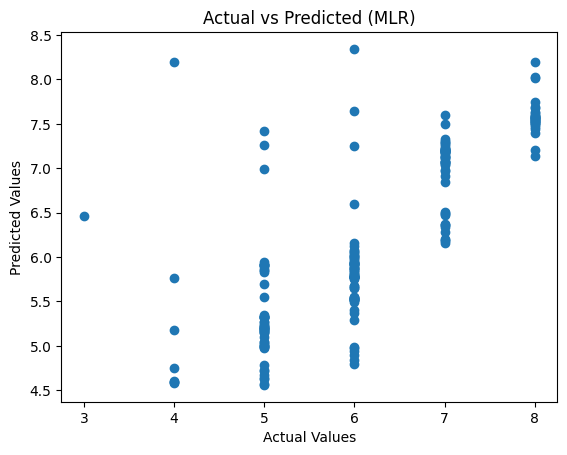

In [36]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (MLR)")
plt.show()

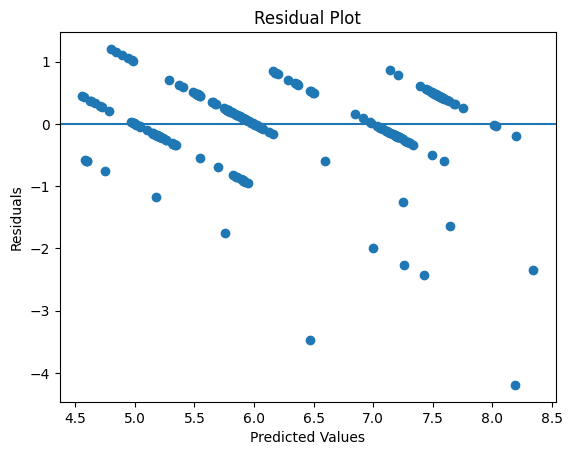

In [37]:
residuals = y_test - y_pred

plt.figure()
plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

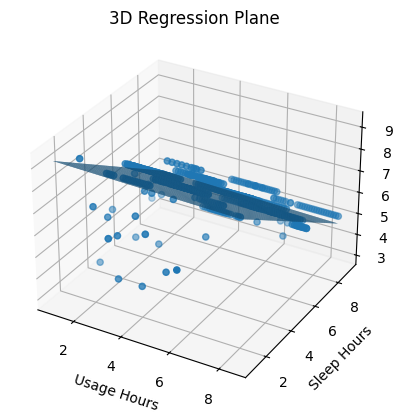

In [38]:
from mpl_toolkits.mplot3d import Axes3D
# Use only 2 features for visualization
X = mlr_df[['Avg_Daily_Usage_Hours','Addicted_Score']]
y = mlr_df["Mental_Health_Score"]
model = LinearRegression()
model.fit(X, y)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Scatter plot
ax.scatter(X.iloc[:,0], X.iloc[:,1], y)
# Create grid
x_surf, y_surf = np.meshgrid(
    np.linspace(X.iloc[:,0].min(), X.iloc[:,0].max(), 100),
    np.linspace(X.iloc[:,1].min(), X.iloc[:,1].max(), 100)
)
z_surf = model.intercept_ + model.coef_[0]*x_surf + model.coef_[1]*y_surf
# Surface plot
ax.plot_surface(x_surf, y_surf, z_surf)
ax.set_xlabel("Usage Hours")
ax.set_ylabel("Sleep Hours")
ax.set_zlabel("Addicted Score")
plt.title("3D Regression Plane")
plt.show()

4th model: classification model.
Dependent/target variable: 'Affects_Academic_Performance'
independent variables: 

In [39]:
mlr_df.columns

Index(['Academic_Level', 'Avg_Daily_Usage_Hours',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score', 'Conflicts_Over_Social_Media', 'Addicted_Score'],
      dtype='object')

In [40]:
X=mlr_df.drop(['Affects_Academic_Performance'],axis=1)
Y=mlr_df['Affects_Academic_Performance']

In [41]:
X

,Academic_Level,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
0,2,5.2,6.5,6,3,8
1,0,2.1,7.5,8,0,3
2,2,6.0,5.0,5,4,9
3,1,3.0,7.0,7,1,4
4,0,4.5,6.0,6,2,7
...,...,...,...,...,...,...
725,2,4.0,7.0,4,1,2
726,2,2.0,7.5,7,1,2
727,2,2.0,8.0,5,0,5
728,2,4.0,7.0,6,1,6


In [42]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,random_state=1)
from sklearn.linear_model import LogisticRegression
classifier=LogisticRegression()
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)
y_pred_proba=classifier.predict_proba(x_test)[:,1]
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
print("Confusion matrix: \n",confusion_matrix(y_test,y_pred))
print("Accuracy score: ",accuracy_score(y_test,y_pred))
print("Classification report",classification_report(y_test,y_pred))

Confusion matrix: 
 [[55  0]
 [ 3 88]]
Accuracy score:  0.9794520547945206
Classification report               precision    recall  f1-score   support

           0       0.95      1.00      0.97        55
           1       1.00      0.97      0.98        91

    accuracy                           0.98       146
   macro avg       0.97      0.98      0.98       146
weighted avg       0.98      0.98      0.98       146



In [43]:
# this model is highly accurate

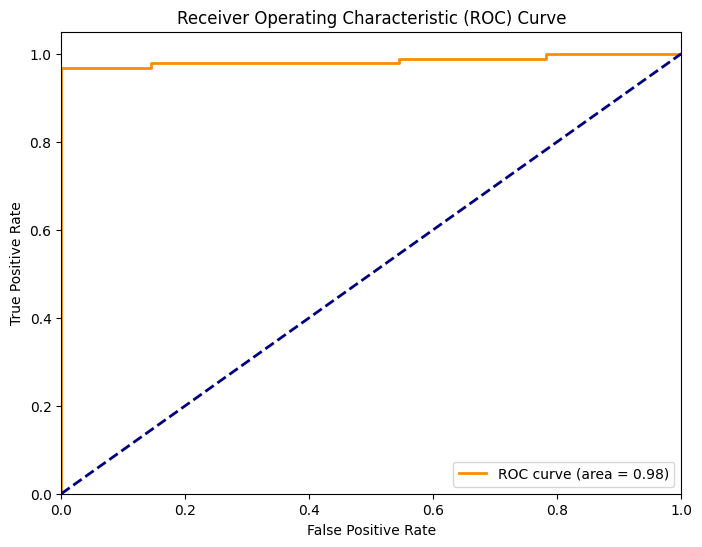

In [44]:
from sklearn.metrics import roc_curve,auc
fpr,tpr, thresholds=roc_curve(y_test,y_pred_proba)
roc_auc=auc(fpr,tpr)

# plot of roc_auc

plt.figure(figsize=(8, 6))  # Create a new figure with a specified size
plt.plot(fpr, tpr, color='darkorange', linewidth=2, label='ROC curve (area = %0.2f)' % roc_auc)  # Plot ROC curve,
plt.plot([0, 1], [0, 1], color='navy', linewidth=2, linestyle='--')  # Plot the diagonal line representing random guessing
plt.xlim([0.0, 1.0])  # Set x-axis limits
plt.ylim([0.0, 1.05])  # Set y-axis limits
plt.xlabel('False Positive Rate')  # Set x-axis label
plt.ylabel('True Positive Rate')  # Set y-axis label
plt.title('Receiver Operating Characteristic (ROC) Curve')  # Set plot title
plt.legend(loc="lower right")  # Add legend to the plot
plt.show()  # Show the plot

In [45]:
# accuracy of this model is very high
new_pred_levels=np.where(y_pred_proba>0.4,1,0)

In [54]:
pd.Series(new_pred_levels).value_counts()

1    92
0    54
Name: count, dtype: int64

In [47]:
confusion_matrix(y_test,new_pred_levels)

array([[51,  4],
       [ 3, 88]])

In [48]:
accuracy_score(y_test,new_pred_levels)

0.952054794520548

In [49]:
print(classification_report(y_test,new_pred_levels))

              precision    recall  f1-score   support

           0       0.94      0.93      0.94        55
           1       0.96      0.97      0.96        91

    accuracy                           0.95       146
   macro avg       0.95      0.95      0.95       146
weighted avg       0.95      0.95      0.95       146



In [50]:
# cross validation
from sklearn.model_selection import KFold
cv=KFold(n_splits=5)
from sklearn.model_selection import cross_val_score
acc=cross_val_score(model,x_train,y_train,cv=cv)
print("mean Accuracy after cross validation is :", np.mean(acc))

mean Accuracy after cross validation is : 0.6767674697359102
